In [1]:
import tensorflow as tf
from tensorflow  import keras
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras  import layers

In [2]:
(X_train , y_train) , (X_test, y_test)  = mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 7s 1us/step 


In [3]:
import matplotlib.pyplot as plt

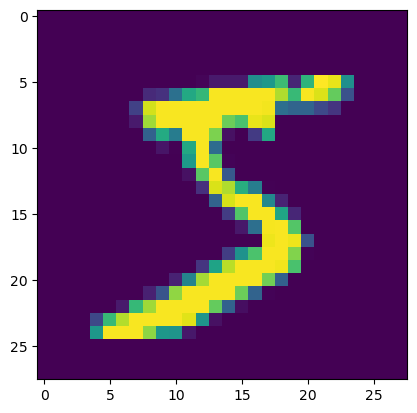

In [8]:
plt.imshow(X_train[0])
plt.show()

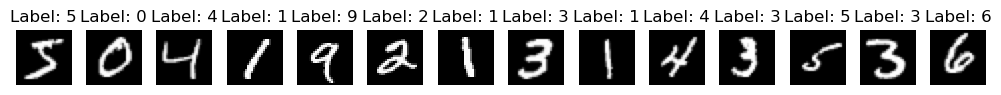

In [14]:
plt.figure(figsize=(10, 3))
for i in range(14):
    plt.subplot(1, 14, i +1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

### Normalized Images

In [15]:
X_train.shape
X_test.shape

(10000, 28, 28)

In [16]:
y_train.shape
y_test.shape

(10000,)

In [24]:
X_train = X_train/255.0 
X_test = X_test/255.0

In [ ]:
grayscale  0,1  (black, white)
rgb  (red , green , blue)

In [25]:
X_train.shape

(60000, 28, 28)

In [45]:
X_train=X_train.reshape(60000, 784)
X_test = X_test.reshape(10000,784)

split = int(X_train.shape[0]*0.8)

x_val = X_train[split:]
y_val = y_train[split:]
X_train = X_train[:split]
y_train = y_train[:split]

In [38]:
y_train.shape[0]

60000

In [46]:
model = keras.Sequential([
    layers.Input(shape=(784,)),
    layers.Dense(512, activation='relu'),
    layers.Dense(256, activation='relu'),
    layers.Dense(10, activation='softmax')
])

In [28]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 512)                 │         401,920 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 256)                 │         131,328 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 10)                  │           2,570 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 535,818 (2.04 MB)

 Trainable params: 535,818 (2.04 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
binary_crossentropy
categorical_crossentropy
sparse_categorical_crossentropy

In [47]:
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [48]:
history = model.fit(X_train, y_train, epochs=10, batch_size=512, validation_data=(x_val,y_val))

Epoch 1/10
94/94 ━━━━━━━━━━━━━━━━━━━━ 5s 31ms/step - accuracy: 0.8859 - loss: 0.4135 - val_accuracy: 0.9509 - val_loss: 0.1708
Epoch 2/10
94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.9583 - loss: 0.1428 - val_accuracy: 0.9621 - val_loss: 0.1264
Epoch 3/10
94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.9721 - loss: 0.0948 - val_accuracy: 0.9687 - val_loss: 0.0998
Epoch 4/10
94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.9807 - loss: 0.0662 - val_accuracy: 0.9728 - val_loss: 0.0906
Epoch 5/10
94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.9866 - loss: 0.0472 - val_accuracy: 0.9748 - val_loss: 0.0787
Epoch 6/10
94/94 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step - accuracy: 0.9896 - loss: 0.0362 - val_accuracy: 0.9742 - val_loss: 0.0871
Epoch 7/10
94/94 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - accuracy: 0.9931 - loss: 0.0257 - val_accuracy: 0.9753 - val_loss: 0.0828
Epoch 8/10
94/94 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - accuracy: 0.9950 - loss: 0.0187 - val_accuracy: 0.9768 - v

In [49]:
model.evaluate(X_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9781 - loss: 0.0785


[0.0784853994846344, 0.9781000018119812]

In [50]:
model.evaluate(X_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9805 - loss: 0.0674


[0.0674394890666008, 0.9804999828338623]

### Prediction

In [52]:
!pip install gradio

Defaulting to user installation because normal site-packages is not writeable
  Using cached audioop_lts-0.2.2-cp313-abi3-win_amd64.whl.metadata (2.0 kB)
INFO: pip is looking at multiple versions of fastapi to determine which version is compatible with other requirements. This could take a while.
   ---------------------------------------- 0.0/31.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/31.3 MB ? eta -:--:--
   ---------------------------------------- 0.3/31.3 MB ? eta -:--:--
   - -------------------------------------- 0.8/31.3 MB 1.8 MB/s eta 0:00:18
   - -------------------------------------- 0.8/31.3 MB 1.8 MB/s eta 0:00:18
   - -------------------------------------- 1.3/31.3 MB 1.4 MB/s eta 0:00:22
   -- ------------------------------------- 1.8/31.3 MB 1.6 MB/s eta 0:00:19
   -- ------------------------------------- 2.1/31.3 MB 1.6 MB/s eta 0:00:19
   -- ------------------------------------- 2.1/31.3 MB 1.6 MB/s eta 0:00:19
   --- -----------------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [53]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import gradio as gr

In [54]:
def predict_image(image_path):
    img = Image.open(image_path).convert('L')
    img = img.resize((28, 28))
    img_array = np.array(img)
    img_array = img_array.reshape(1, 784)
    img_array = img_array / 255.0
    prediction = model.predict(img_array)
    predicted_class = np.argmax(prediction)
    return predicted_class

In [ ]:
app = gr.Interface(fn=predict_image, inputs=gr.Image(type="filepath"), outputs="text")

In [ ]:
demo.close()

In [ ]:
app.launch(share=True,debug=True )

* Running on local URL:  http://127.0.0.1:7860

Could not create share link. Please check your internet connection or our status page: https://status.gradio.app.


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step
Created dataset file at: .gradio\flagged\dataset1.csv


Traceback (most recent call last):
  File "D:\SMIT\anaconda\Lib\site-packages\PIL\Image.py", line 3471, in open
    fp.seek(0)
    ^^^^^^^
AttributeError: 'NoneType' object has no attribute 'seek'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "C:\Users\HP\AppData\Roaming\Python\Python313\site-packages\gradio\queueing.py", line 882, in process_events
    response = await route_utils.call_process_api(
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
    )
    ^
  File "C:\Users\HP\AppData\Roaming\Python\Python313\site-packages\gradio\route_utils.py", line 410, in call_process_api
    output = await app.get_blocks().process_api(
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    ...<12 lines>...
    )
    ^
  File "C:\Users\HP\AppData\Roaming\Python\Python313\site-packages\gradio\blocks.py", line 2330, in process_api
    result = await self.call_function(
             ^^^^^^^^^^^^^^^^^^^^^^^^^
    ..

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step
